In [1]:
# Import hyperparameter optimization, machine learning, and visualization libraries
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, classification_report
)

# Prevent potential OpenMP runtime library collisions
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


In [2]:
# Load the clothing reviews dataset for classification tuning
data_file = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_file):
    data_file = os.path.join("05-11-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_file)
print(f"Dataset successfully loaded with {df.shape[0]} rows and {df.shape[1]} columns.")
display(df[['Age', 'Department Name', 'Review_Length', 'Sentiment_Compound', 'Recommended IND']].head())


Dataset successfully loaded with 23486 rows and 23 columns.


,Age,Department Name,Review_Length,Sentiment_Compound,Recommended IND
0,33,Intimate,53,0.8932,1
1,34,Dresses,303,0.9729,1
2,60,Dresses,524,0.9427,0
3,50,Bottoms,141,0.7182,1
4,47,Tops,209,0.9436,1


In [3]:
# Feature Extraction: Vectorize customer review text and combine with structured metadata
# Fill null text fields with empty strings
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

# Generate TF-IDF features for top 200 unigrams and bigrams
vectorizer = TfidfVectorizer(max_features=200, stop_words='english', ngram_range=(1, 2))
X_text = vectorizer.fit_transform(df['Full_Review_Text']).toarray()

# Extract continuous demographic, review length, and sentiment metrics
numerical_columns = [
    'Age', 'Positive Feedback Count', 'Review_Length', 'Review_Word_Count',
    'Exclamation_Count', 'Sentiment_Compound', 'Sentiment_Pos',
    'Sentiment_Neg', 'Positive_Word_Count', 'Negative_Word_Count', 'Fit_Issue_Word_Count'
]
X_num = df[numerical_columns].fillna(0).values

# One-hot encode garment department categories
department_dummies = pd.get_dummies(df['Department Name'].fillna('Unknown'), prefix='dept', drop_first=True)
X_dept = department_dummies.values

# Assemble complete matrix of features
X = np.hstack([X_text, X_num, X_dept])
y = df['Recommended IND'].values
print(f"Assembled feature space: {X.shape[0]} samples with {X.shape[1]} features.")


Assembled feature space: 23486 samples with 216 features.


In [4]:
# Stratified Data Split: 85% for cross-validation tuning and 15% holdout test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)
print(f"Training/CV size: {X_train.shape[0]}, Holdout Test size: {X_test.shape[0]}")


Training/CV size: 19963, Holdout Test size: 3523


In [5]:
# Load the complete GridSearchCV optimization results table
cv_results_file = "gridsearch_full_parameter_results.csv"
if not os.path.exists(cv_results_file):
    cv_results_file = os.path.join("05-11-2026", "Task 2", "gridsearch_full_parameter_results.csv")

df_results = pd.read_csv(cv_results_file)
df_results['param_max_depth_str'] = df_results['param_max_depth_str'].fillna('None').astype(str)
print("Top 10 Parameter Configurations Ranked by Stratified CV Test ROC-AUC:")
display(df_results.head(10))


Top 10 Parameter Configurations Ranked by Stratified CV Test ROC-AUC:


,param_n_estimators,param_max_depth_str,param_min_samples_split,param_min_samples_leaf,mean_test_roc_auc,std_test_roc_auc,mean_train_roc_auc,Generalization_Gap_ROC_AUC,mean_test_f1,std_test_f1,mean_train_f1,mean_test_accuracy,std_test_accuracy,rank_test_roc_auc,rank_test_f1,mean_fit_time
0,150,None,2,4,0.911415,0.005092,0.985468,0.074053,0.929429,0.002097,0.963531,0.878267,0.003762,1,11,2.529956
1,150,None,10,4,0.911393,0.004132,0.984848,0.073455,0.930642,0.001932,0.963144,0.880400,0.003363,2,6,2.652613
2,100,None,10,4,0.911373,0.004928,0.984490,0.073117,0.931584,0.001856,0.962153,0.882000,0.003425,3,2,1.506236
3,150,15.0,10,1,0.911015,0.004293,0.986647,0.075632,0.928916,0.002981,0.962055,0.876800,0.005803,4,16,2.145474
4,100,None,2,4,0.910752,0.005467,0.985176,0.074424,0.929182,0.002167,0.963256,0.877867,0.003987,5,12,1.543546
5,150,None,10,1,0.910442,0.004498,0.999135,0.088693,0.931677,0.001813,0.990623,0.882800,0.003304,6,1,3.228700
6,150,15.0,2,4,0.910315,0.004053,0.972945,0.062629,0.929106,0.001759,0.951722,0.877067,0.003593,7,13,2.217179
7,150,15.0,10,4,0.910315,0.005117,0.972151,0.061836,0.929105,0.002232,0.950923,0.876933,0.004592,8,14,2.986441
8,100,15.0,2,4,0.910057,0.004148,0.972609,0.062552,0.928624,0.002036,0.951500,0.876267,0.004101,9,19,1.249234
9,100,15.0,10,1,0.910026,0.004236,0.986544,0.076519,0.929446,0.002375,0.961774,0.877733,0.004725,10,10,1.372840


In [6]:
# Load and display Stratified 5-Fold Cross-Validation Stability Metrics
stability_file = "stratified_kfold_stability_metrics.csv"
if not os.path.exists(stability_file):
    stability_file = os.path.join("05-11-2026", "Task 2", "stratified_kfold_stability_metrics.csv")

df_fold_stability = pd.read_csv(stability_file)
print("Stratified 5-Fold Cross-Validation Metric Stability Across Partitions:")
display(df_fold_stability)


Stratified 5-Fold Cross-Validation Metric Stability Across Partitions:


,Configuration,Fold_1_ROC_AUC,Fold_2_ROC_AUC,Fold_3_ROC_AUC,Fold_4_ROC_AUC,Fold_5_ROC_AUC,Mean_ROC_AUC,Std_Dev,Variance,Stability_Rating
0,Trees=150_Depth=None_Split=2_Leaf=4,0.9091,0.9196,0.9121,0.9040,0.9123,0.9114,0.0051,0.000026,High
1,Trees=150_Depth=None_Split=10_Leaf=4,0.9064,0.9179,0.9107,0.9081,0.9139,0.9114,0.0041,0.000017,Exceptional (< 0.005 std)
2,Trees=100_Depth=None_Split=10_Leaf=4,0.9050,0.9188,0.9109,0.9076,0.9146,0.9114,0.0049,0.000024,Exceptional (< 0.005 std)
3,Trees=150_Depth=15_Split=10_Leaf=1,0.9092,0.9176,0.9112,0.9045,0.9126,0.9110,0.0043,0.000018,Exceptional (< 0.005 std)
4,Trees=100_Depth=None_Split=2_Leaf=4,0.9088,0.9195,0.9111,0.9025,0.9118,0.9108,0.0055,0.000030,High


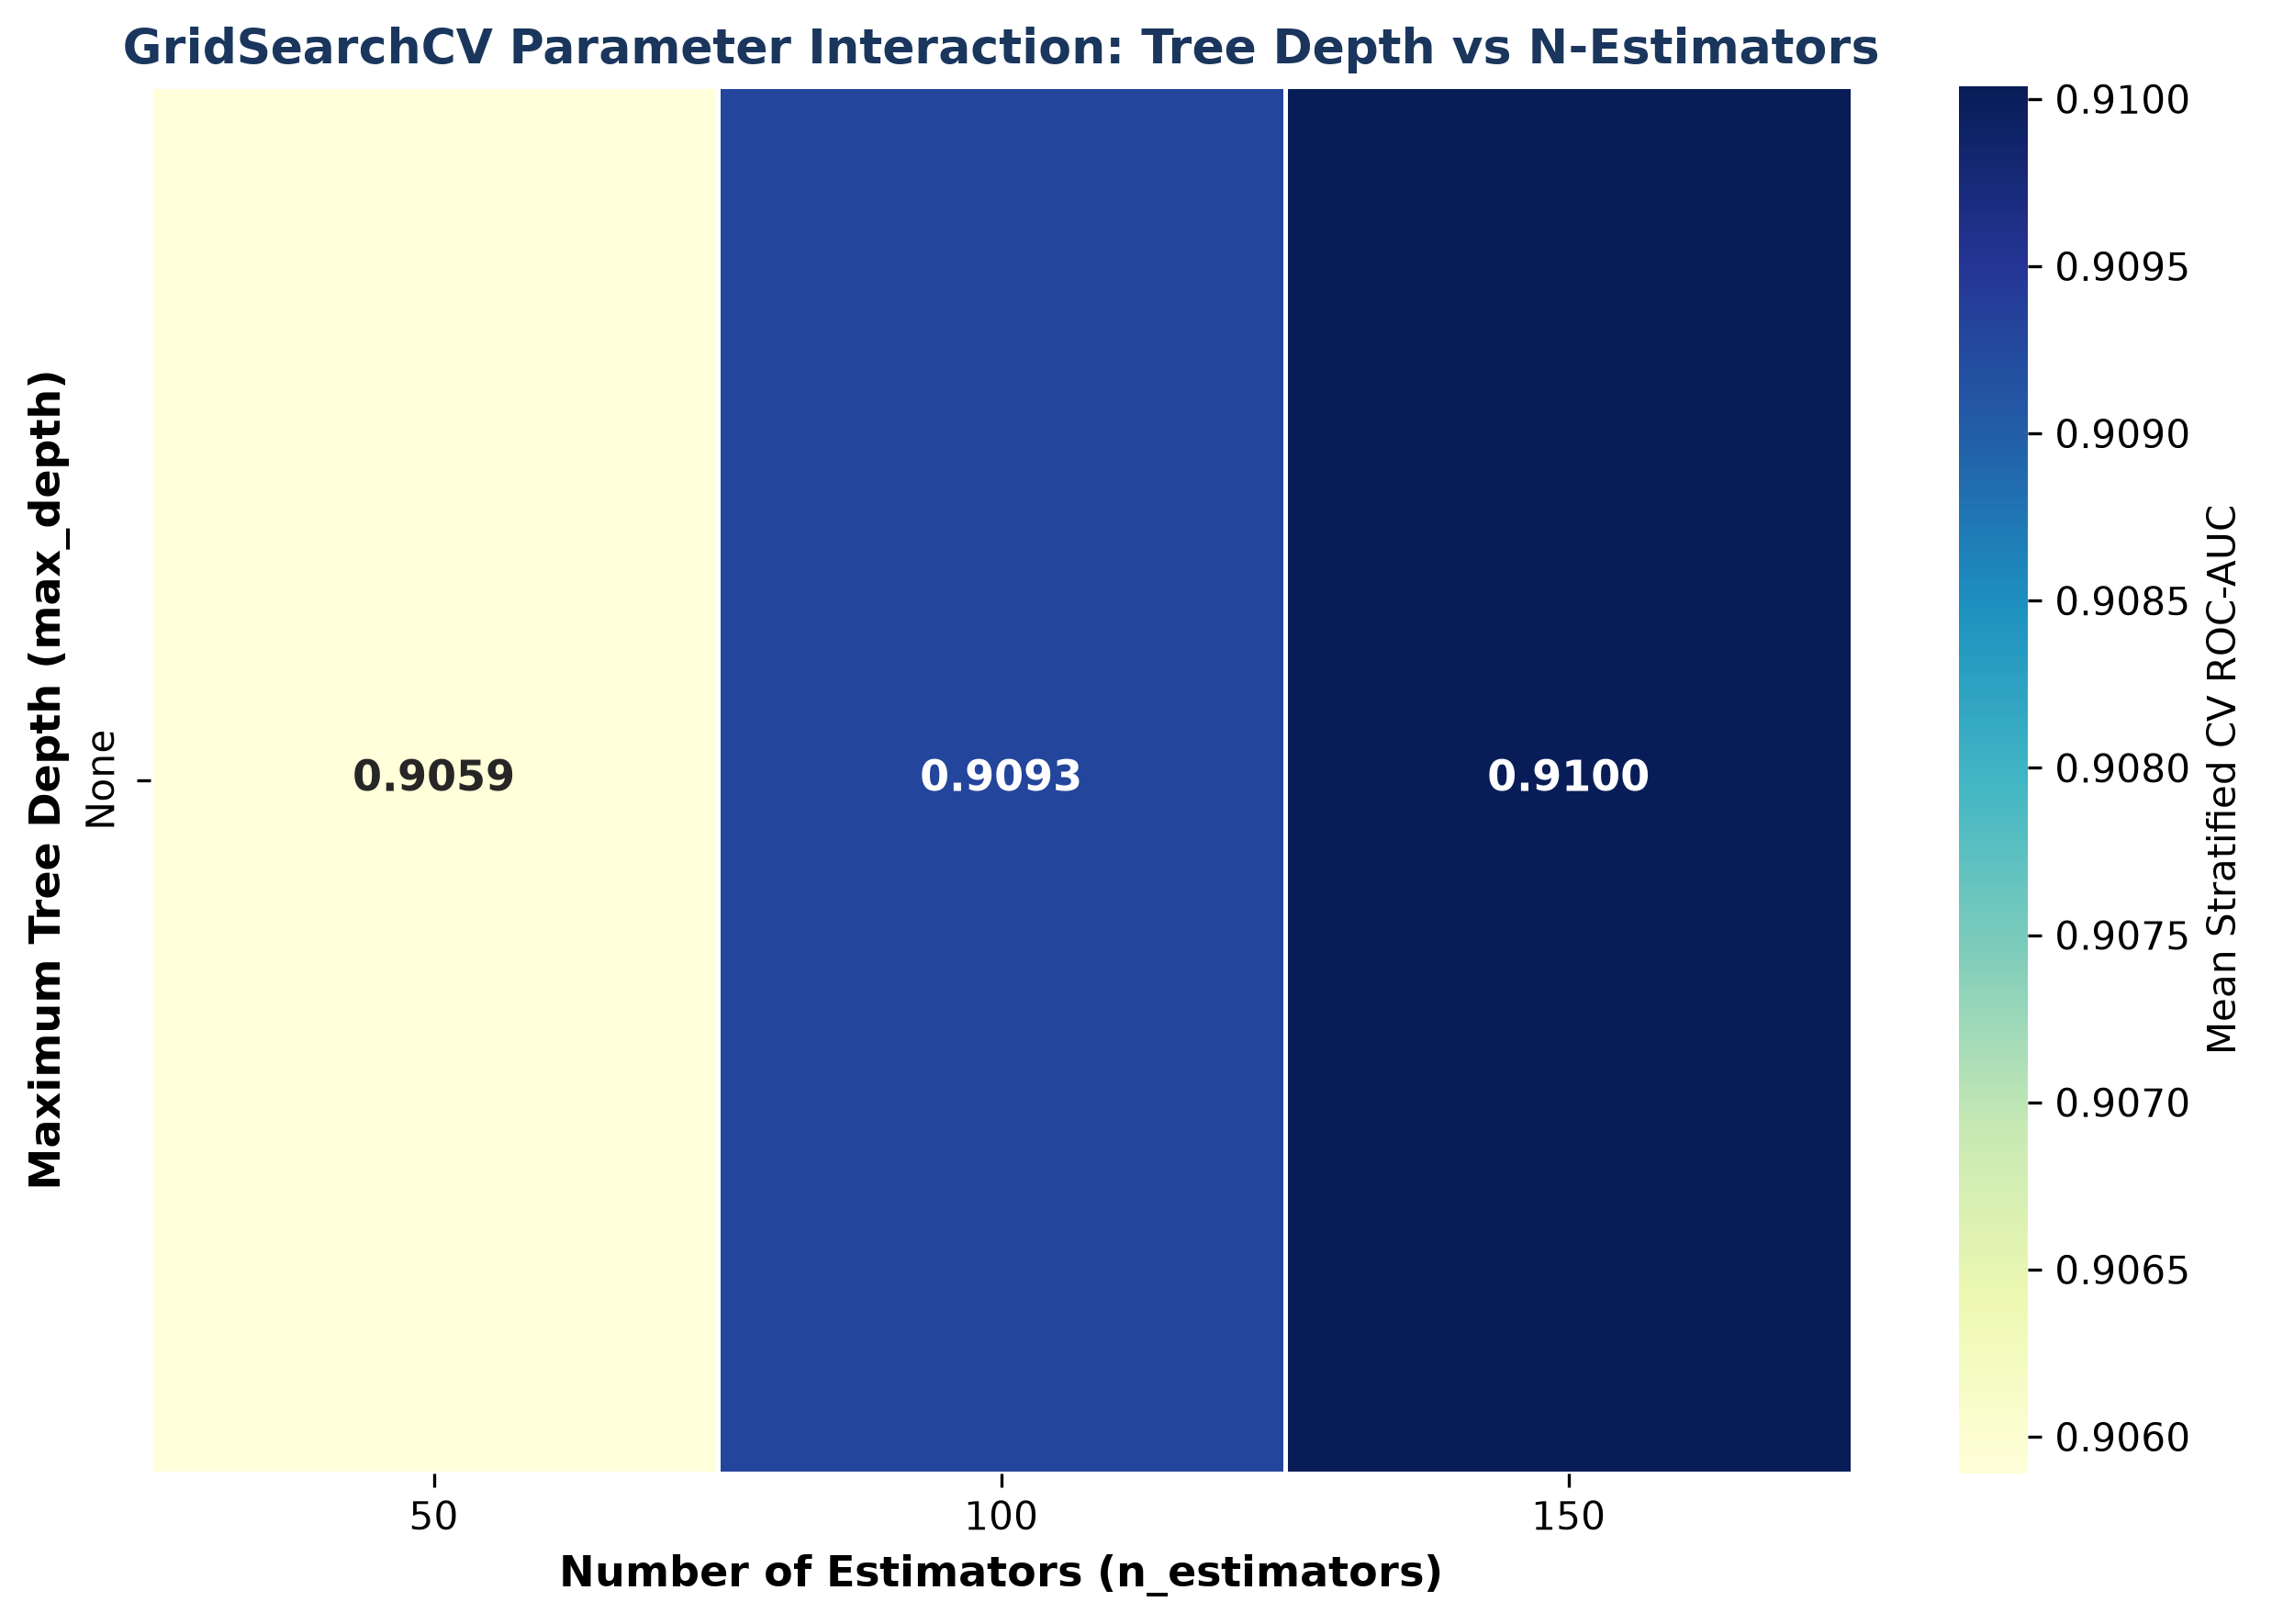

In [7]:
# Display Figure 1: 2D Interaction Heatmap of Tree Depth vs Number of Estimators
heatmap_matrix = df_results.pivot_table(index='param_max_depth_str', columns='param_n_estimators', values='mean_test_roc_auc', aggfunc='mean')
depth_ordering = [d for d in ['6', '10', '15', 'None'] if d in heatmap_matrix.index]
if len(depth_ordering) > 0:
    heatmap_matrix = heatmap_matrix.reindex(depth_ordering)

fig, ax = plt.subplots(figsize=(8.5, 6), dpi=300)
sns.heatmap(
    heatmap_matrix, annot=True, fmt=".4f", cmap="YlGnBu",
    cbar_kws={'label': 'Mean Stratified CV ROC-AUC'}, ax=ax,
    linewidths=1.2, linecolor='white', annot_kws={'fontsize': 11, 'fontweight': 'bold'}
)
ax.set_title("GridSearchCV Parameter Interaction: Tree Depth vs N-Estimators", fontsize=12.5, fontweight='bold', color='#1A365D')
ax.set_xlabel("Number of Estimators (n_estimators)", fontsize=11, fontweight='bold')
ax.set_ylabel("Maximum Tree Depth (max_depth)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


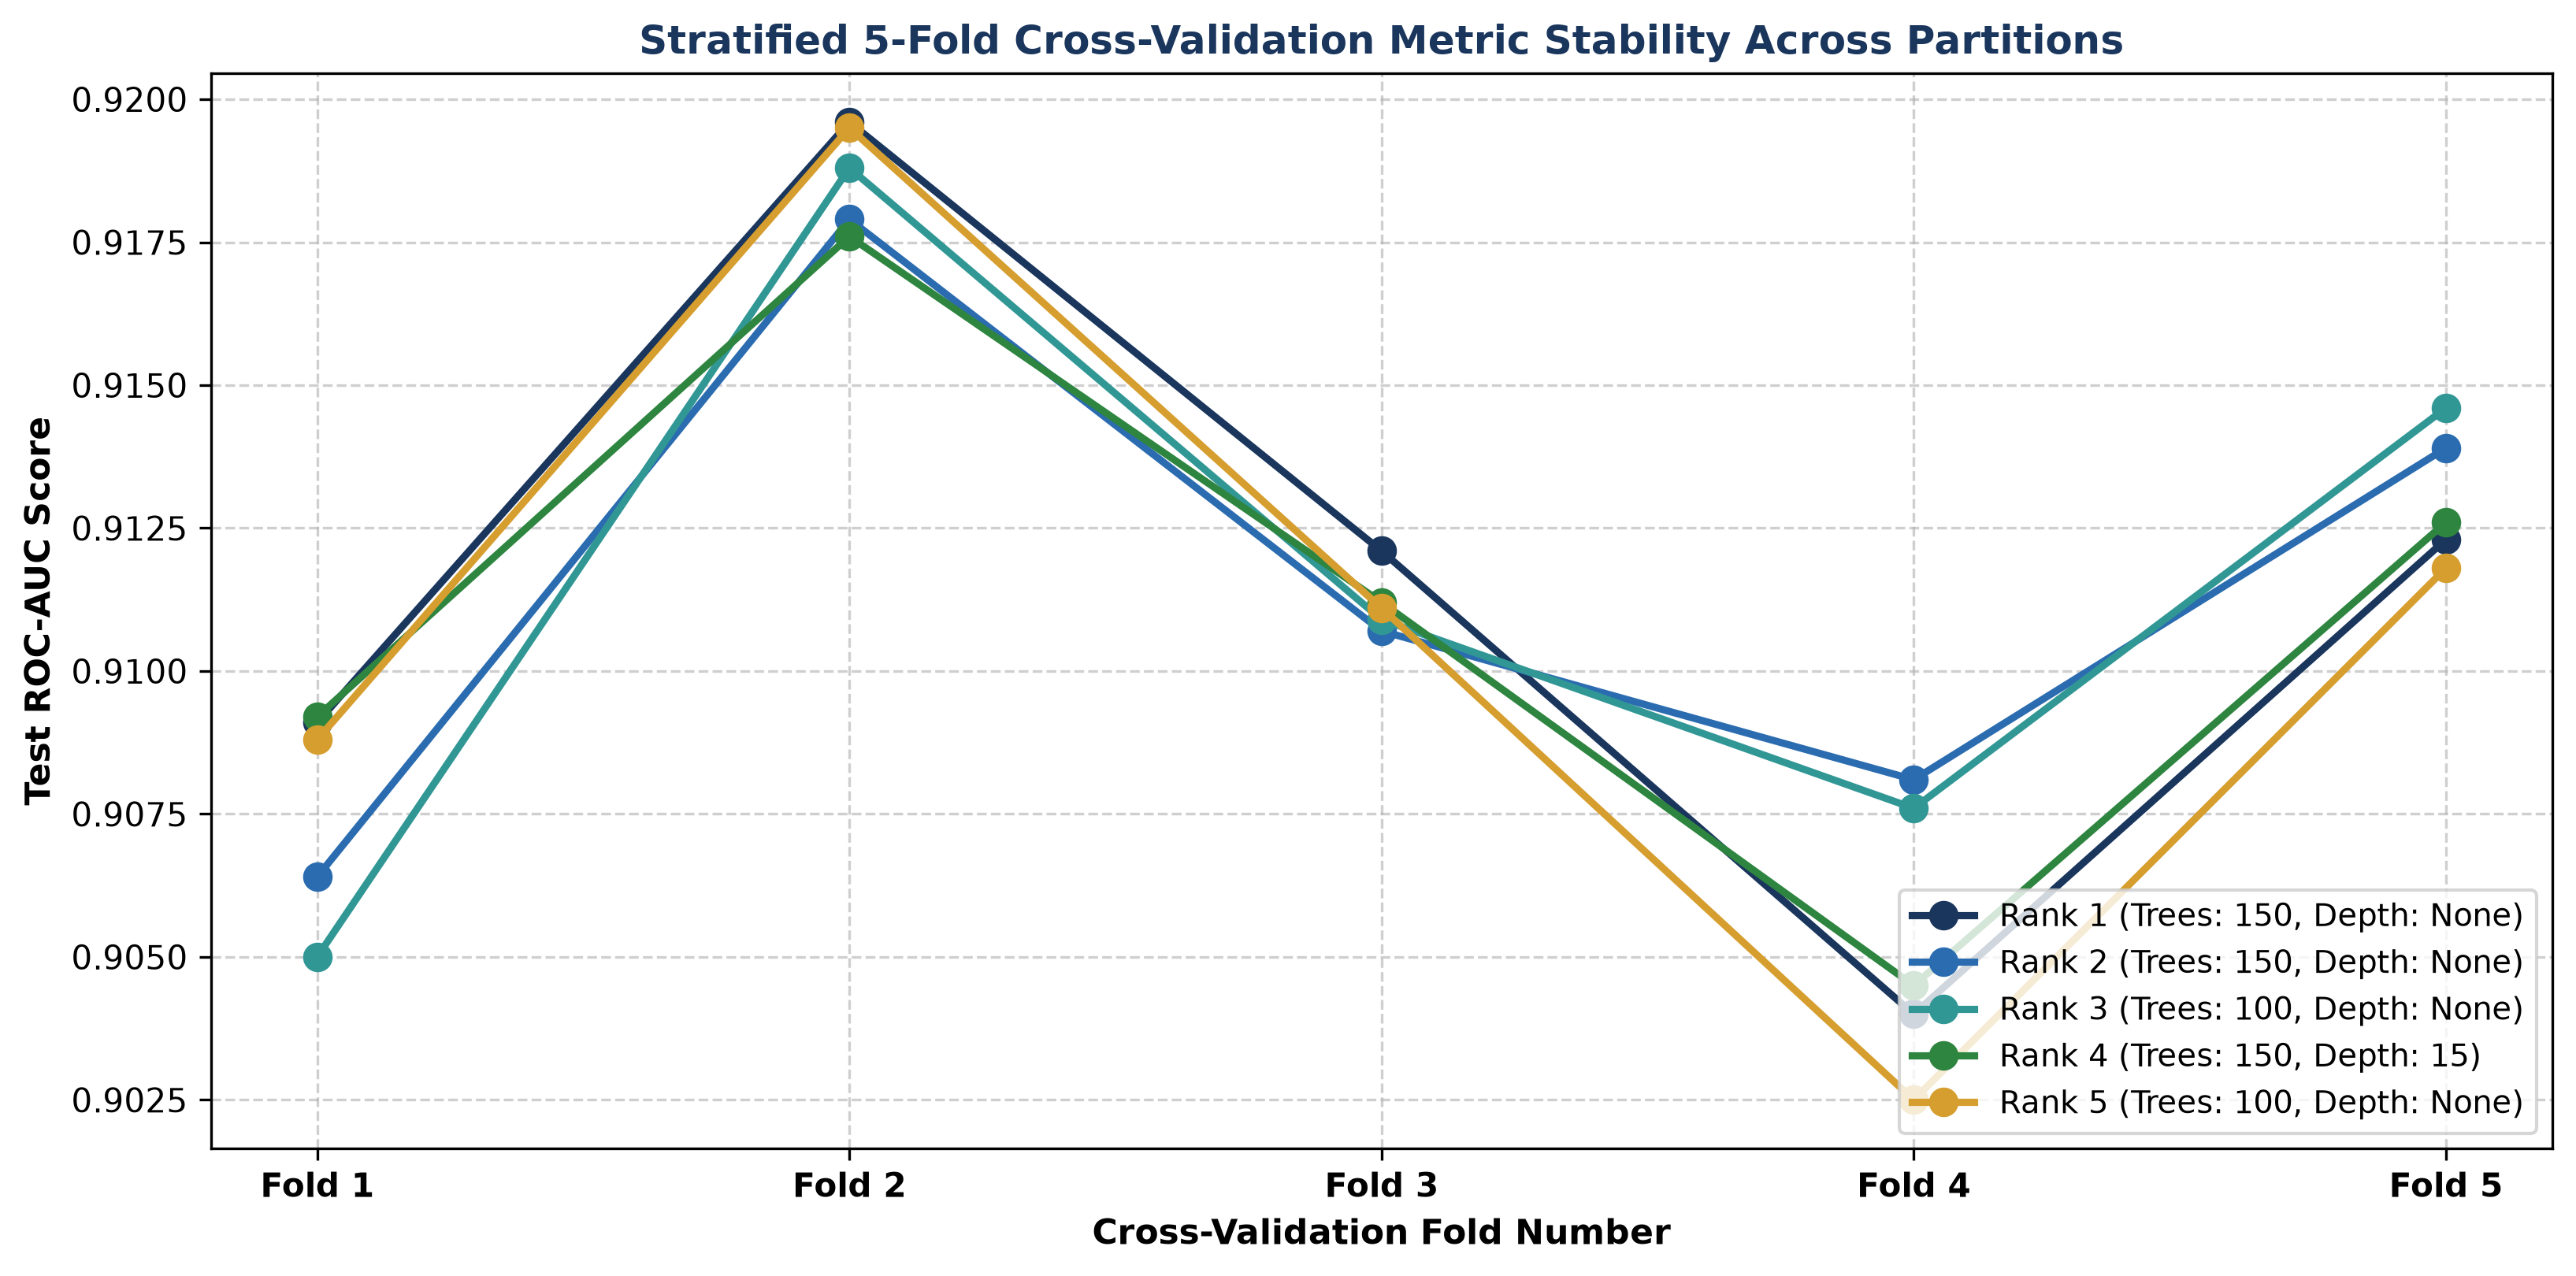

In [8]:
# Display Figure 2: K-Fold Score Stability Across All 5 Partitions
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)
x_ticks = np.arange(1, 6)
color_palette = ['#1A365D', '#2B6CB0', '#319795', '#2E8540', '#D69E2E']

for i, row in df_fold_stability.iterrows():
    fold_scores = [row[f'Fold_{k}_ROC_AUC'] for k in range(1, 6)]
    cfg_label = row['Configuration'].split('_Depth=')[0].replace('Trees=', 'Trees: ') + ', Depth: ' + row['Configuration'].split('_Depth=')[1].split('_')[0]
    ax.plot(x_ticks, fold_scores, marker='o', linewidth=2.2, markersize=8, label=f"Rank {i+1} ({cfg_label})", color=color_palette[i])

ax.set_title("Stratified 5-Fold Cross-Validation Metric Stability Across Partitions", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Cross-Validation Fold Number", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Test ROC-AUC Score", fontsize=10.5, fontweight='bold')
ax.set_xticks(x_ticks)
ax.set_xticklabels([f"Fold {k}" for k in x_ticks], fontsize=10, fontweight='bold')
ax.legend(loc='lower right', frameon=True, fontsize=9.5)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


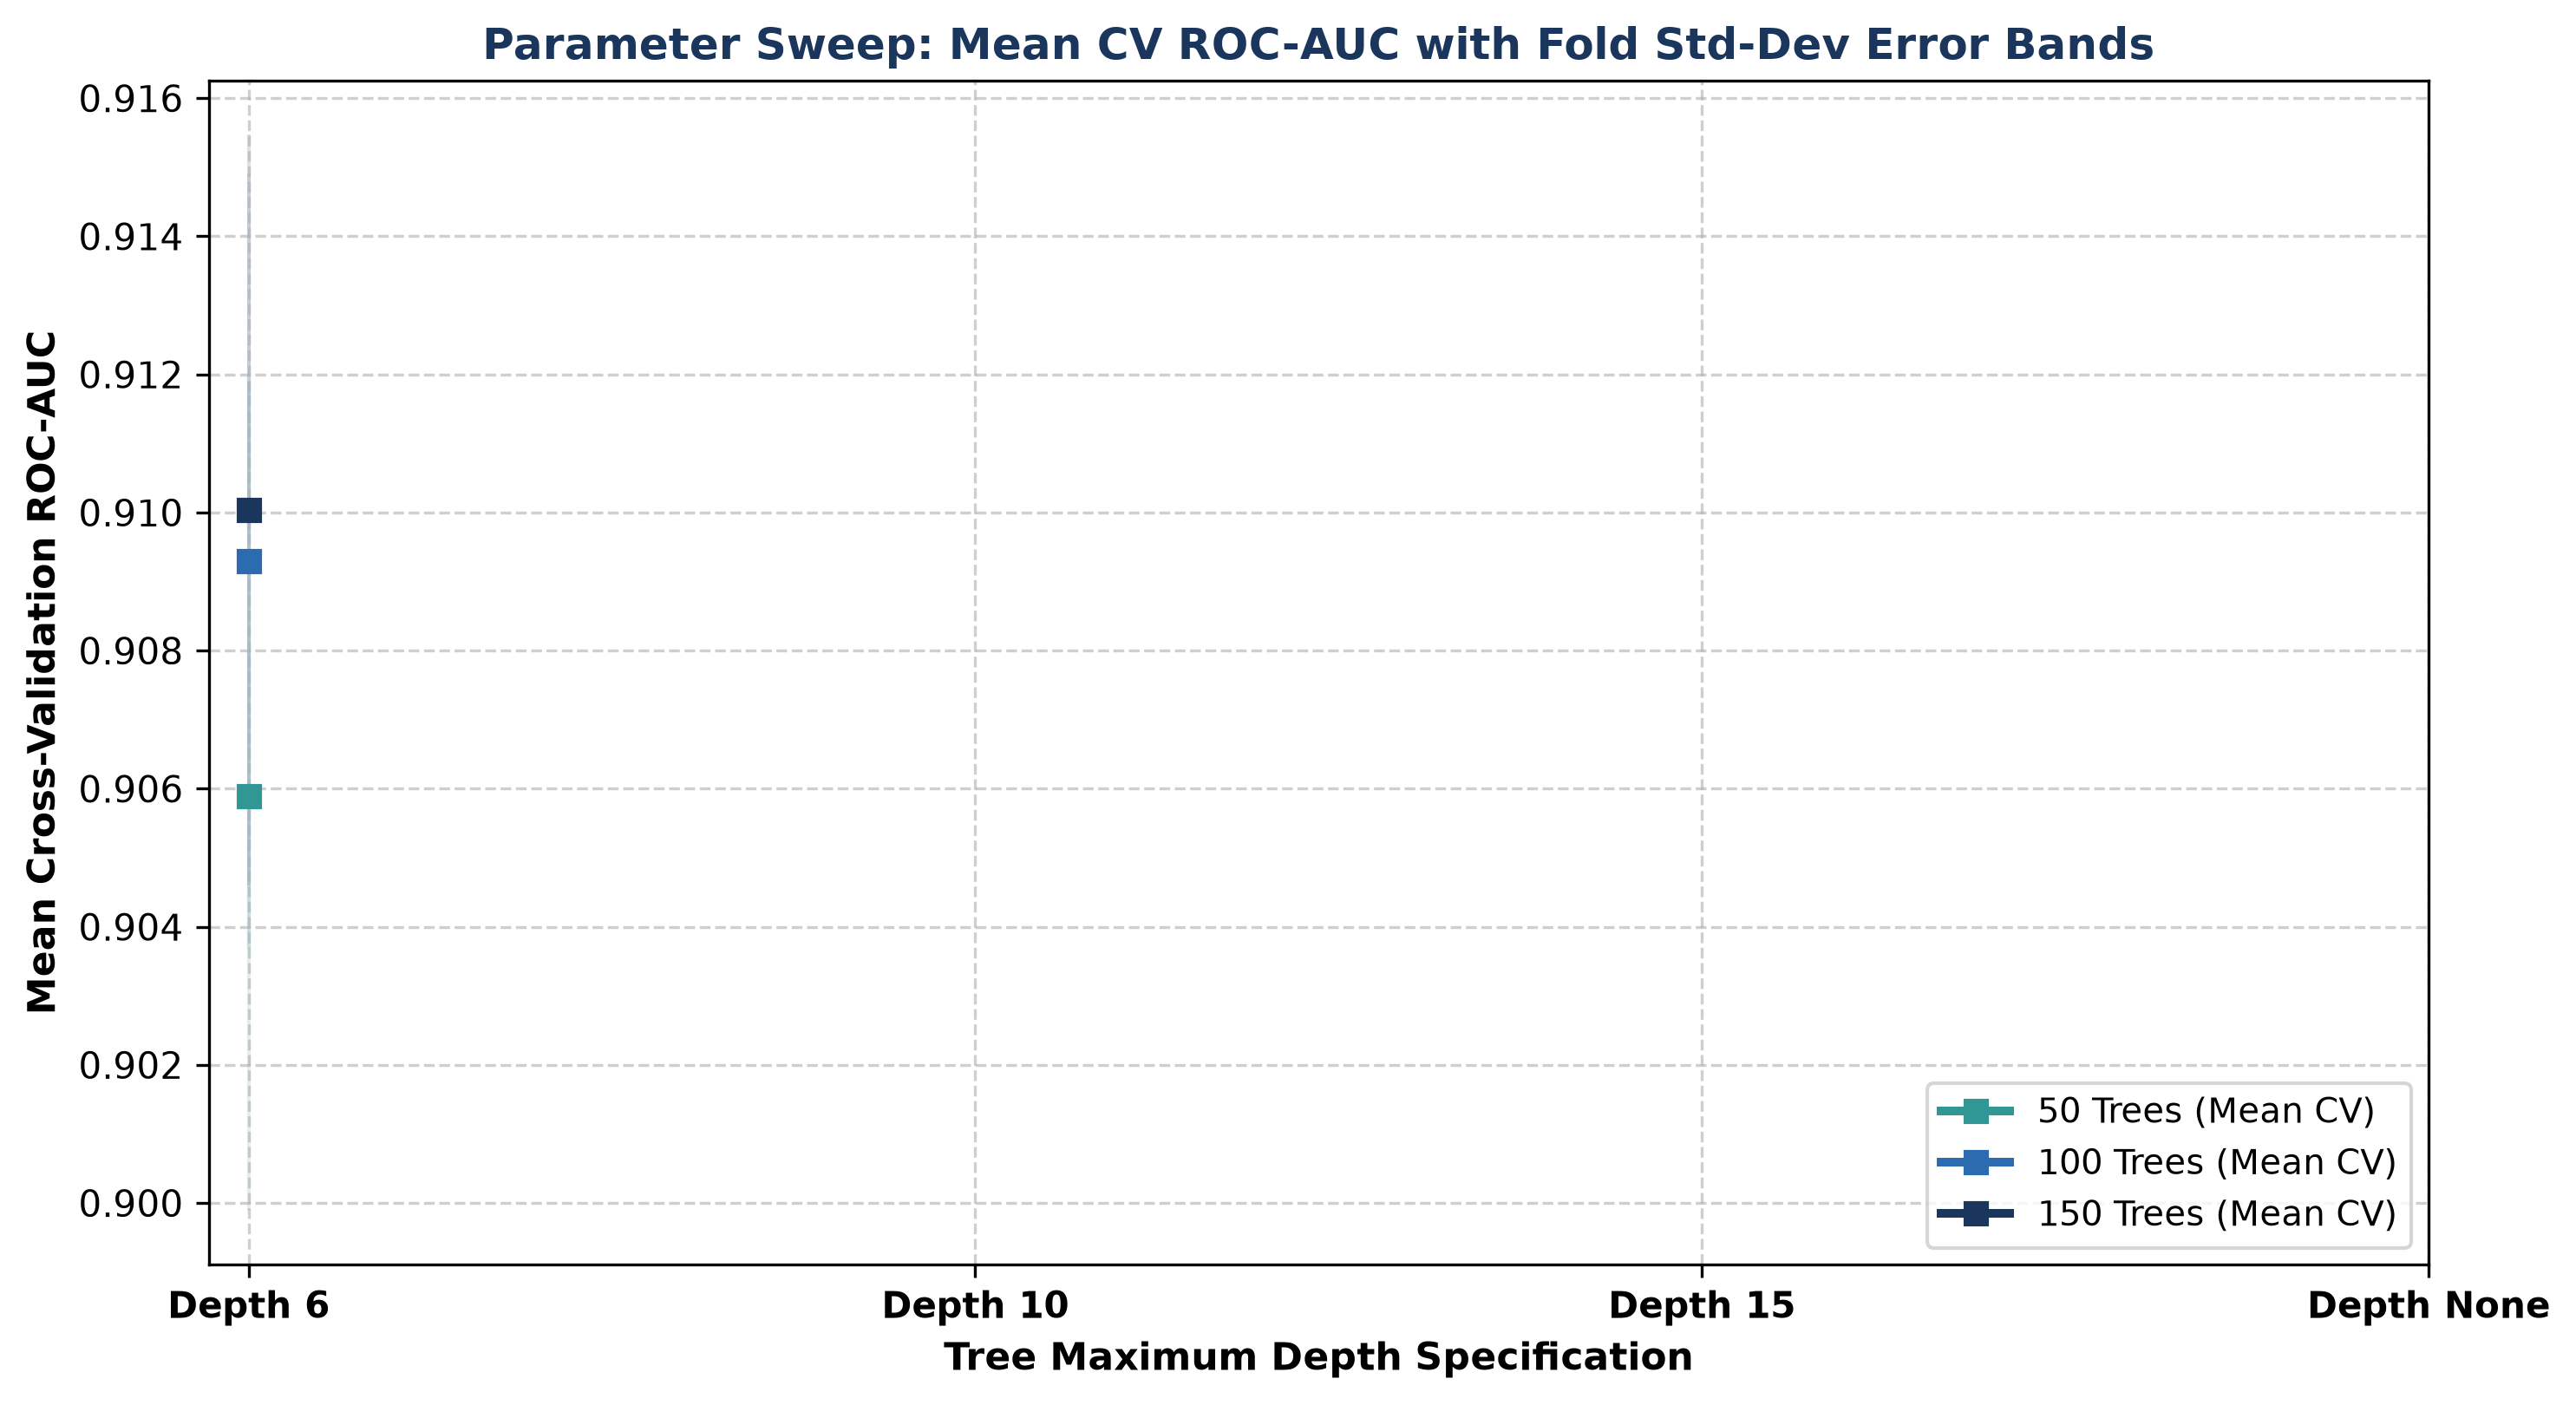

In [9]:
# Display Figure 3: Parameter Sweep with Fold Standard Deviation Error Bands
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
depth_labels = ['6', '10', '15', 'None']
tree_counts = [50, 100, 150]
tree_color_map = {'50': '#319795', '100': '#2B6CB0', '150': '#1A365D'}

for n_trees in tree_counts:
    subset = df_results[df_results['param_n_estimators'] == n_trees].groupby('param_max_depth_str').agg({
        'mean_test_roc_auc': 'mean',
        'std_test_roc_auc': 'mean'
    })
    ordering = [d for d in depth_labels if d in subset.index]
    if len(ordering) > 0:
        subset = subset.reindex(ordering)
    means = subset['mean_test_roc_auc'].values
    stds = subset['std_test_roc_auc'].values
    x_positions = np.arange(len(means))
    ax.plot(x_positions, means, marker='s', linewidth=2.4, label=f'{n_trees} Trees (Mean CV)', color=tree_color_map[str(n_trees)])
    ax.fill_between(x_positions, means - stds, means + stds, color=tree_color_map[str(n_trees)], alpha=0.15)

ax.set_title("Parameter Sweep: Mean CV ROC-AUC with Fold Std-Dev Error Bands", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Tree Maximum Depth Specification", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Mean Cross-Validation ROC-AUC", fontsize=10.5, fontweight='bold')
ax.set_xticks(np.arange(len(depth_labels)))
ax.set_xticklabels([f"Depth {d}" for d in depth_labels], fontsize=10, fontweight='bold')
ax.legend(loc='lower right', frameon=True, fontsize=9.5)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


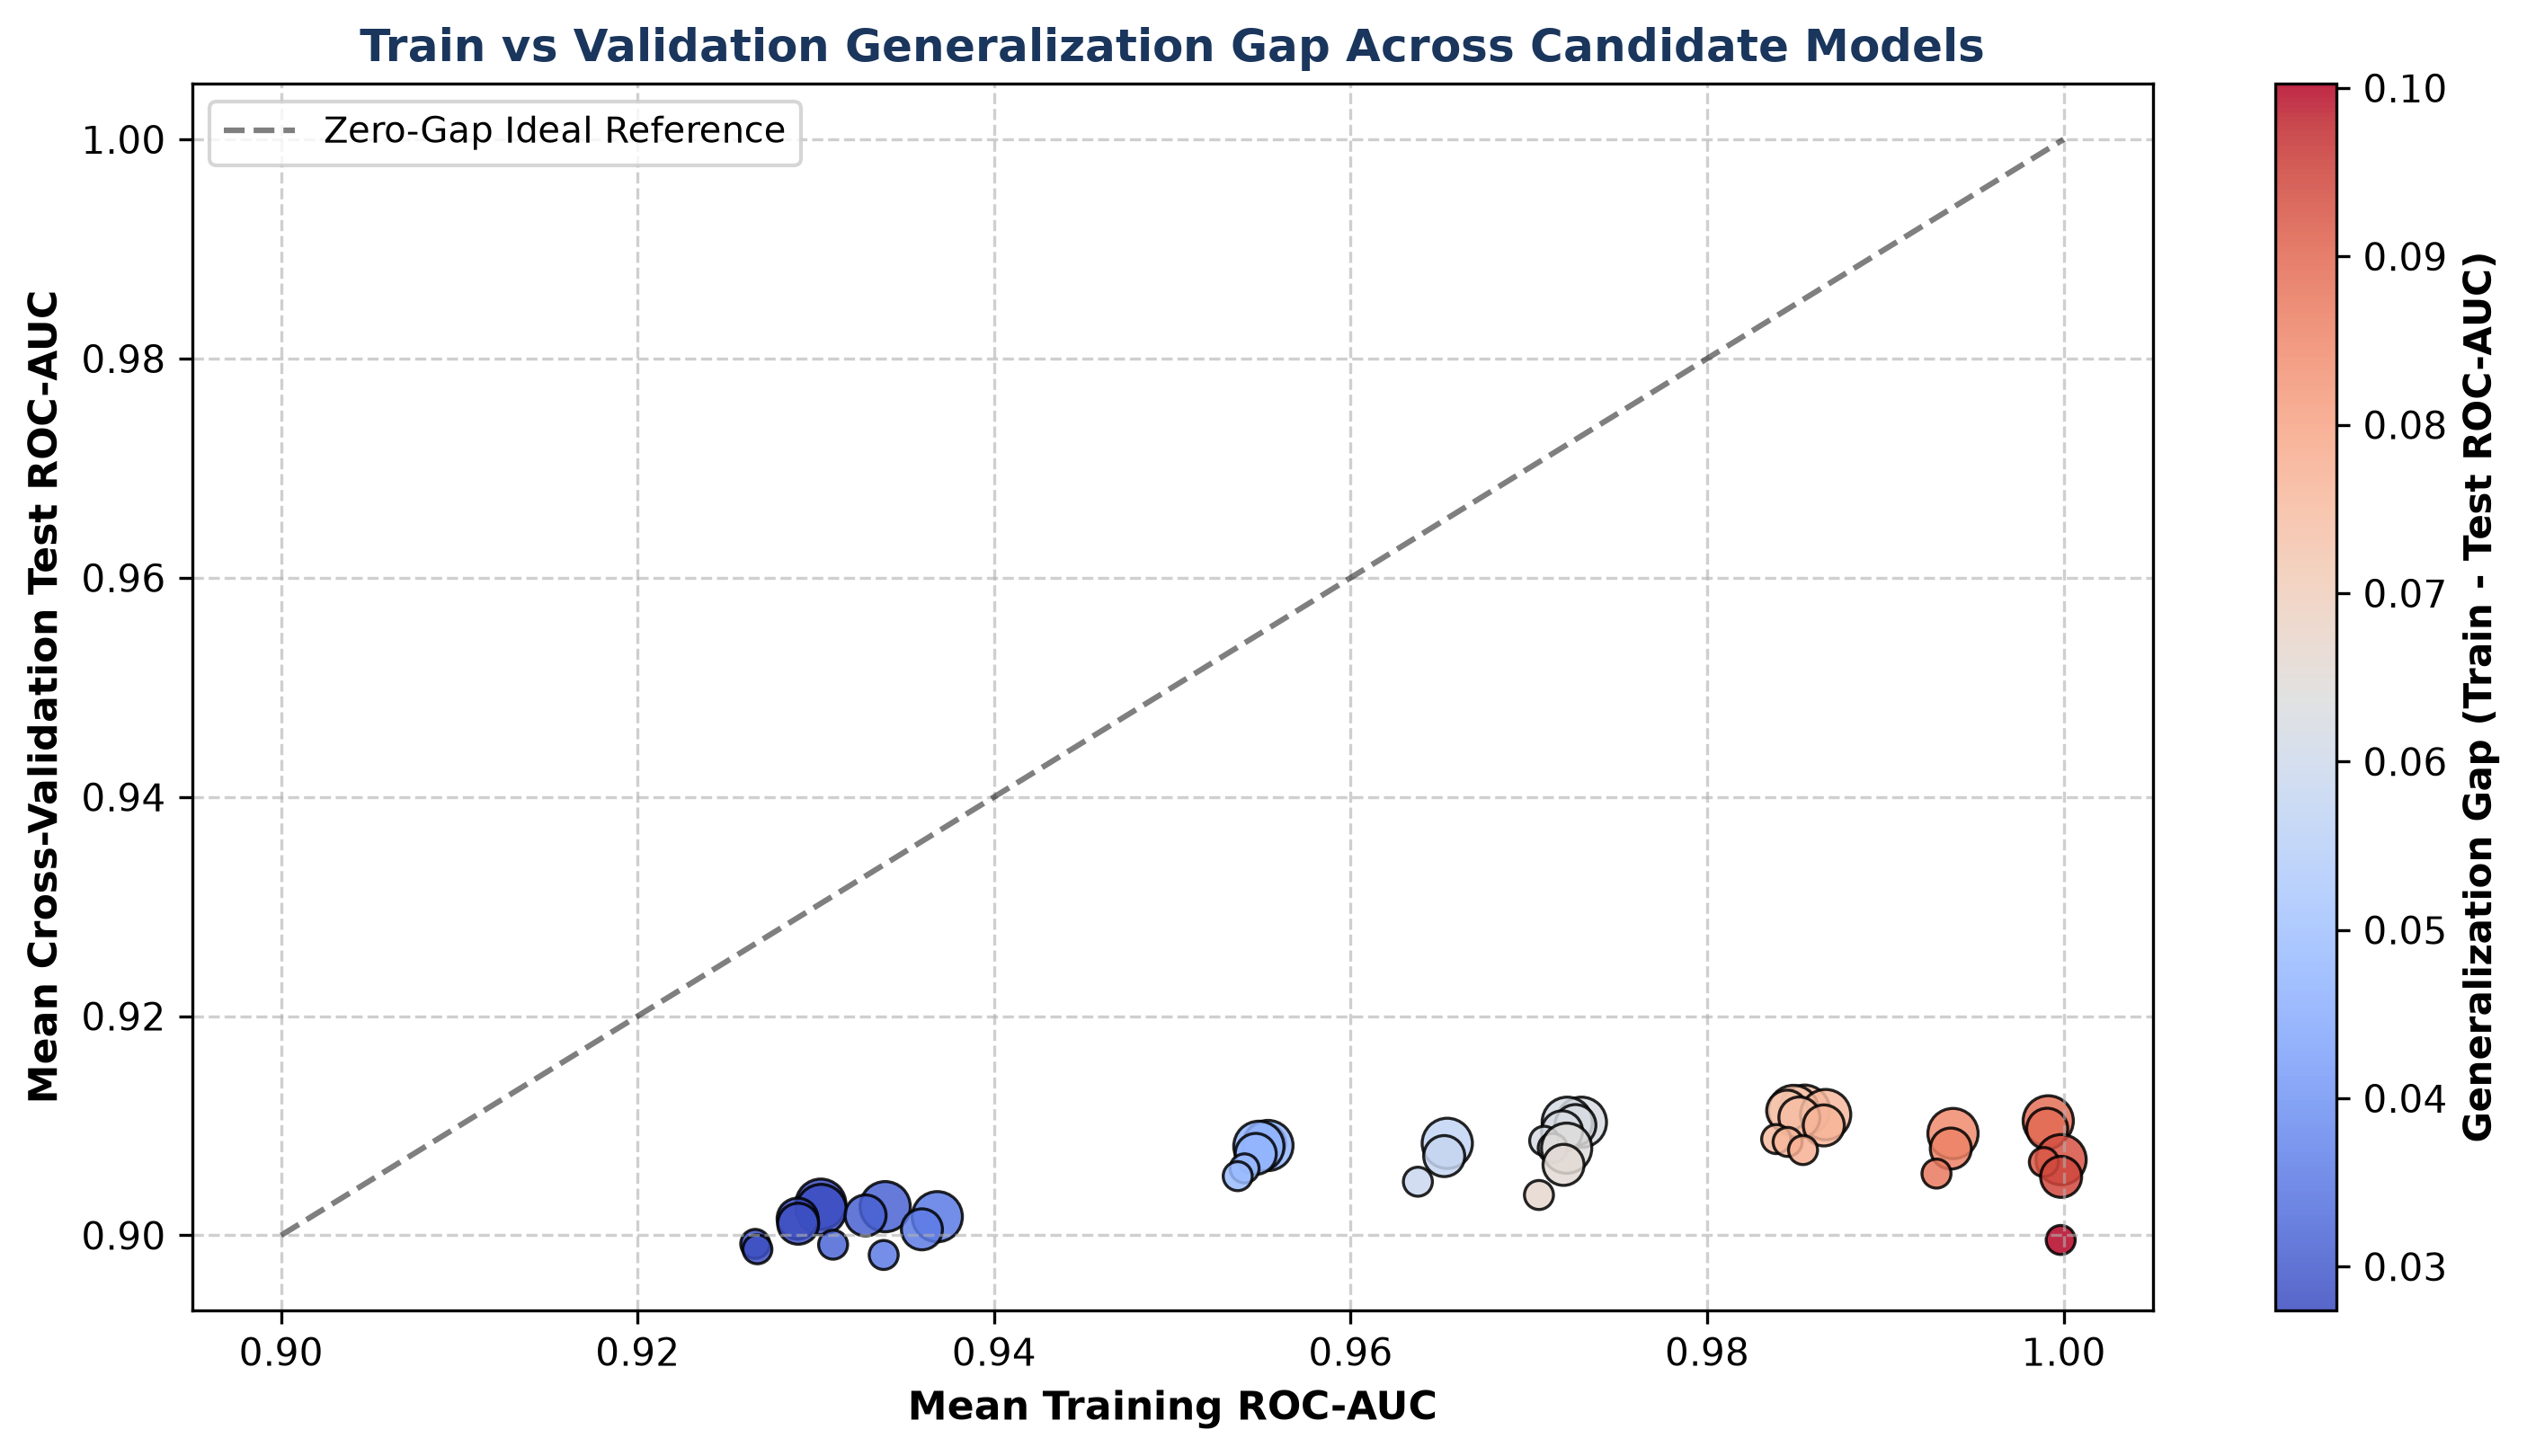

In [10]:
# Display Figure 4: Train vs Validation Generalization Gap Scatter Plot
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
scatter_plot = ax.scatter(
    df_results['mean_train_roc_auc'], df_results['mean_test_roc_auc'],
    c=df_results['Generalization_Gap_ROC_AUC'], cmap='coolwarm',
    s=df_results['param_n_estimators'] * 1.2, edgecolor='black', linewidth=0.8, alpha=0.85
)
cbar = plt.colorbar(scatter_plot, ax=ax)
cbar.set_label('Generalization Gap (Train - Test ROC-AUC)', fontsize=10, fontweight='bold')

# Reference identity line indicating perfect zero-gap generalization
ax.plot([0.90, 1.0], [0.90, 1.0], 'k--', alpha=0.5, label='Zero-Gap Ideal Reference')

ax.set_title("Train vs Validation Generalization Gap Across Candidate Models", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Mean Training ROC-AUC", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Mean Cross-Validation Test ROC-AUC", fontsize=10.5, fontweight='bold')
ax.legend(loc='upper left', frameon=True, fontsize=9.5)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [11]:
# Load and display the optimal estimator performance on the holdout test set
best_model_file = "best_estimator_configuration_and_performance.csv"
if not os.path.exists(best_model_file):
    best_model_file = os.path.join("05-11-2026", "Task 2", "best_estimator_configuration_and_performance.csv")

df_best_eval = pd.read_csv(best_model_file)
print("Optimal Estimator Performance on Holdout Test Set:")
display(df_best_eval)


Optimal Estimator Performance on Holdout Test Set:


,Model_Family,Best_N_Estimators,Best_Max_Depth,Best_Min_Samples_Split,Best_Min_Samples_Leaf,CV_Mean_ROC_AUC,Holdout_Test_Accuracy,Holdout_Test_Precision,Holdout_Test_Recall,Holdout_Test_F1,Holdout_Test_ROC_AUC,Holdout_Test_Log_Loss,Total_Tuning_Time_Sec
0,RandomForestClassifier_GridSearchCV,150,NaN,2,4,0.9114,0.8771,0.8896,0.971,0.9285,0.915,0.279,170.68
